In [8]:
library('tidymodels')
library('palmerpenguins')
library('vip')

theme_set(theme_gray(base_size = 16))

── Attaching packages ────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels 1.4.1 ──
✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
── Conflicts ───────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Learn how to get started at https://www.tidymodels.org/start/

Attaching package: ‘palmerpenguins’

The foll

In [10]:
penguins2 = penguins |>
    drop_na()

penguins2 |> head()

  species island    bill_length_mm bill_depth_mm flipper_length_mm body_mass_g
1 Adelie  Torgersen 39.1           18.7          181               3750       
2 Adelie  Torgersen 39.5           17.4          186               3800       
3 Adelie  Torgersen 40.3           18.0          195               3250       
4 Adelie  Torgersen 36.7           19.3          193               3450       
5 Adelie  Torgersen 39.3           20.6          190               3650       
6 Adelie  Torgersen 38.9           17.8          181               3625       
  sex    year
1 male   2007
2 female 2007
3 female 2007
4 female 2007
5 male   2007
6 female 2007

  species island    bill_length_mm bill_depth_mm flipper_length_mm body_mass_g
1 Adelie  Torgersen 39.1           18.7          181               3750       
2 Adelie  Torgersen 39.5           17.4          186               3800       
3 Adelie  Torgersen 40.3           18.0          195               3250       
4 Adelie  Torgersen 36.7           19.3          193               3450       
5 Adelie  Torgersen 39.3           20.6          190               3650       
6 Adelie  Torgersen 38.9           17.8          181               3625       
  sex    year
1 male   2007
2 female 2007
3 female 2007
4 female 2007
5 male   2007
6 female 2007

  species island    bill_length_mm bill_depth_mm flipper_length_mm body_mass_g
1 Adelie  Torgersen 39.1           18.7          181               3750       
2 Adelie  Torgersen 39.5           17.4          186               3800       
3 Adelie  Torgersen 40.3           18.0          195               3250       
4 Adelie  Torgersen 36.7           19.3          193               3450       
5 Adelie  Torgersen 39.3           20.6          190               3650       
6 Adelie  Torgersen 38.9           17.8          181               3625       
  sex    year
1 male   2007
2 female 2007
3 female 2007
4 female 2007
5 male   2007
6 female 2007

## Use random forests to model `bill_length_mm`

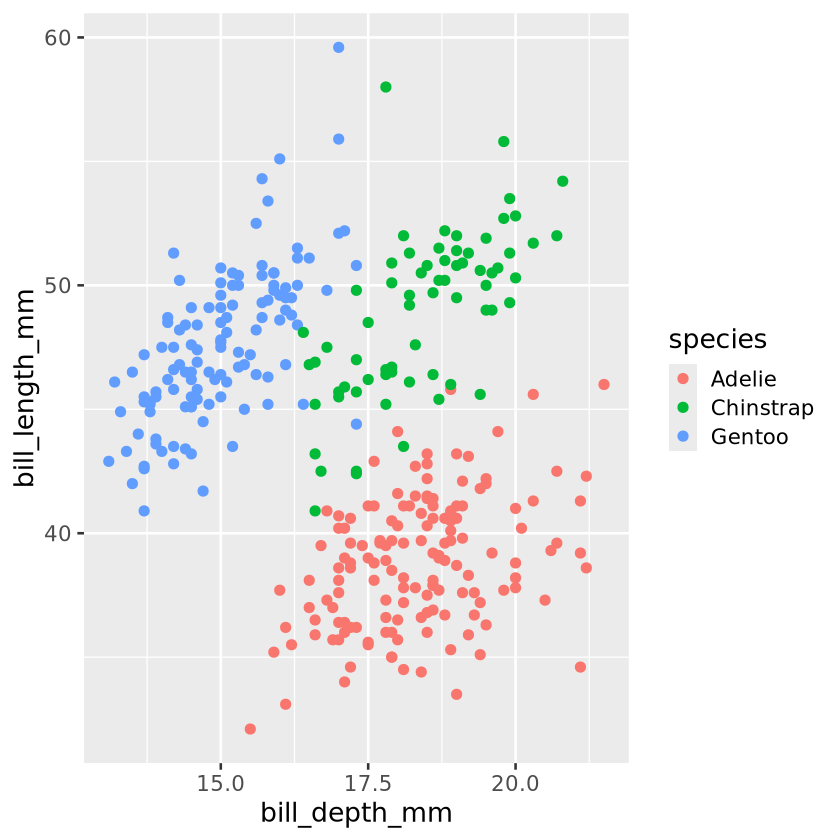

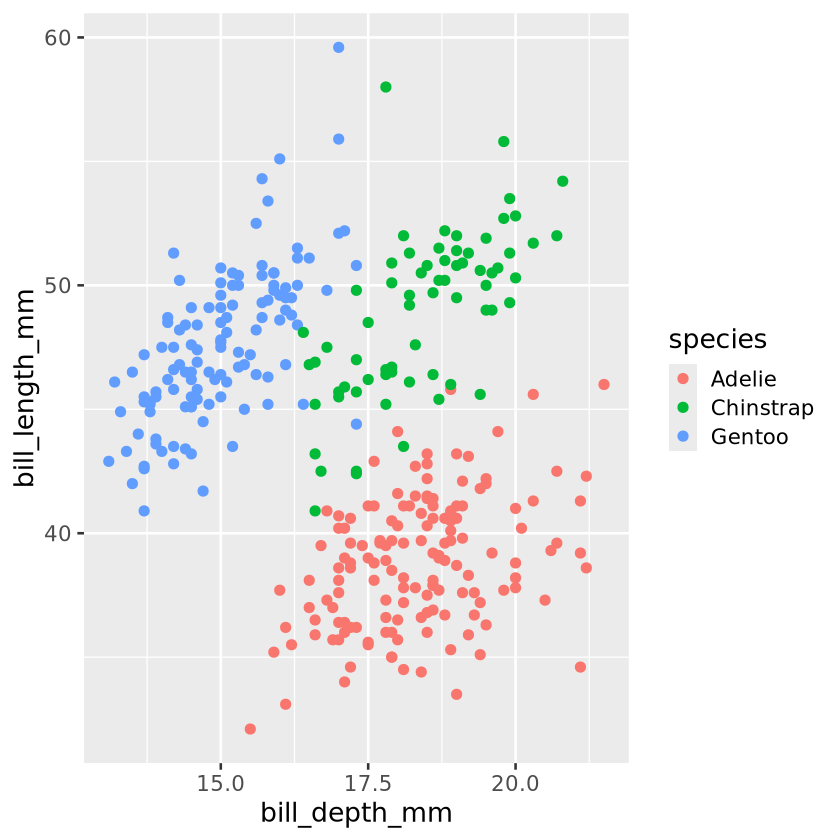

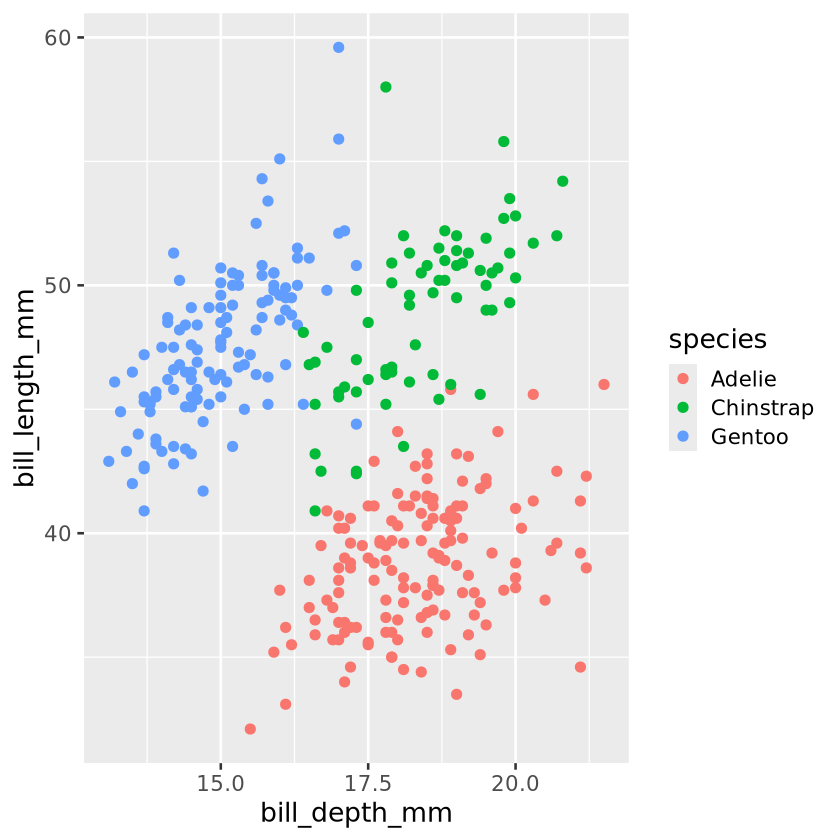

In [12]:
ggplot(penguins2, aes(y=bill_length_mm, x=bill_depth_mm, color=species))+
    geom_point()


In [14]:
mod <-rand_forest()

In [16]:
mod = rand_forest() |> 
   set_engine('ranger', importance = 'impurity') |>
   set_mode('regression')

In [17]:
mod_fit=mod |> fit(bill_length_mm ~., data=penguins2)
mod_fit

parsnip model object

Ranger result

Call:
 ranger::ranger(x = maybe_data_frame(x), y = y, importance = "impurity",      num.threads = 1, verbose = FALSE, seed = sample.int(10^5,          1)) 

Type:                             Regression 
Number of trees:                  500 
Sample size:                      333 
Number of independent variables:  7 
Mtry:                             2 
Target node size:                 5 
Variable importance mode:         impurity 
Splitrule:                        variance 
OOB prediction error (MSE):       5.291678 
R squared (OOB):                  0.8230583 

In [20]:
predict(mod_fit, new_data=penguins2) |>
    bind_cols(penguins2) |> ggplot(aes(y=bill_length_mm, x=bill_depth_mm, color=species))+
    geom_point() + geom_line(aes(y=.pred))

    .pred    species   island    bill_length_mm bill_depth_mm flipper_length_mm
1   39.10528 Adelie    Torgersen 39.1           18.7          181              
2   38.26382 Adelie    Torgersen 39.5           17.4          186              
3   38.96526 Adelie    Torgersen 40.3           18.0          195              
4   37.57608 Adelie    Torgersen 36.7           19.3          193              
5   38.94444 Adelie    Torgersen 39.3           20.6          190              
6   38.63505 Adelie    Torgersen 38.9           17.8          181              
7   40.64216 Adelie    Torgersen 39.2           19.6          195              
8   38.68998 Adelie    Torgersen 41.1           17.6          182              
9   39.30326 Adelie    Torgersen 38.6           21.2          191              
10  38.70429 Adelie    Torgersen 34.6           21.1          198              
11  37.79912 Adelie    Torgersen 36.6           17.8          185              
12  38.36570 Adelie    Torgersen 38.7   

In [ ]:
rec = recipe(bill_length_mm ~ ., data = penguins2) |>
    step_rm(year) |>
    step_dummy(sex, island, species)

rec |> prep() |> juice() |> head()

In [ ]:
wf = workflow() |> 
  add_recipe(rec) |> 
  add_model(mod)

wf_fit = wf |> fit(data = penguins2)

wf_fit

In [ ]:
outcomes = augment(wf_fit |> extract_fit_parsnip(), 
                   new_data = rec |> prep() |> juice())

outcomes |> head()

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 5)

ggplot(outcomes) +
    geom_point(aes(x = bill_depth_mm, y = bill_length_mm)) + 
    geom_point(aes(x = bill_depth_mm, y = .pred), color = 'steelblue', size = 3,
               alpha = 0.5) +
    geom_segment(aes(x = bill_depth_mm, xend = bill_depth_mm, y = .pred, yend = bill_length_mm), 
                 color = 'firebrick',
                 alpha = 0.25)

## Visualize feature importance

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 4)

wf_fit |> 
  extract_fit_parsnip() |> 
  vip()

## Single random forest

One complete random forest on the penguins data: recipe → workflow → fit → predict.

In [ ]:
rf_spec = rand_forest() |>
    set_engine('ranger', importance = 'impurity') |>
    set_mode('regression')

rf_rec = recipe(bill_length_mm ~ ., data = penguins2) |>
    step_rm(year) |>
    step_dummy(sex, island, species)

rf_wf = workflow() |>
    add_recipe(rf_rec) |>
    add_model(rf_spec)

rf_fit = rf_wf |> fit(data = penguins2)
rf_fit

rf_preds = augment(rf_fit, new_data = penguins2)

ggplot(rf_preds, aes(x = bill_depth_mm, y = bill_length_mm, color = species)) +
    geom_point() +
    geom_point(aes(y = .pred), color = 'steelblue', size = 2, alpha = 0.5)

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 4)

rf_fit |>
    extract_fit_parsnip() |>
    vip()